# BCR — MiXCR и анализ IGH

 Образец `DChu_T7_pbmc_d7COVID2_2`.

**Что делали.** Парные FASTQ прогнали через MiXCR 4.7.0 на учебном сервере МФТИ (Slurm, задача **157721**, статус **COMPLETED**, код выхода **0:0**, время **00:07:48**). На выходе получились клонотипы IGH и отчёты по выравниванию, UMI-коррекции, сборке и QC. Дальше в ноутбуке разбираем уже эти таблицы.

От семинарского ноутбука по TRB этот отличается тем, что здесь цепь IGH, есть UMI, клонотипы собираются по расширенному участку вариабельной области, а образец всего один. Анализ TCR CD4/CD8 лежит в `UCB_homework.ipynb`.

In [ ]:
from pathlib import Path
import os,sys,json,hashlib,random,platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display,Markdown
import repseq
from repseq import io,stats,clone_filter as clf
from repseq.common_functions import get_column_names_from_clonoset
%matplotlib inline
sns.set_theme(style='whitegrid',context='notebook')
plt.rcParams.update({'figure.dpi':105,'savefig.dpi':160,'font.family':'DejaVu Sans'})
ROOT=Path.cwd()
RESULTS=Path(os.environ.get('BCR_RESULTS',str(ROOT/'results_bcr')))
SAMPLE='DChu_T7_pbmc_d7COVID2_2'
SEED=100
ITERATIONS=5
stats.AA_PROPS_PATH=str(Path(repseq.__file__).parent/'resourses/aa_property_table.txt')
def load_report(kind):return json.loads((RESULTS/f'{SAMPLE}.{kind}.report.json').read_text())
align=load_report('align');refine=load_report('refine');assemble=load_report('assemble')
qc_raw=json.loads((RESULTS/'fastq_qc.json').read_text())
qc_report=json.loads((RESULTS/f'{SAMPLE}.qc.json').read_text())
job_status=(RESULTS/'job_157721_status.txt').read_text()
assert 'COMPLETED' in job_status and '0:0' in job_status
assert align['totalReadsProcessed']==qc_raw['paired_reads']==938889
assert '4.7.0' in align['version']
server_hashes={Path(line.split(maxsplit=1)[1].strip()).name:line.split()[0] for line in (RESULTS/'input_fastq.sha256').read_text().splitlines()}
for f in qc_raw['files']:assert server_hashes[f['filename']]==f['sha256']
clone_path=RESULTS/f'{SAMPLE}.clones_IGH.tsv'
raw=io.read_clonoset(str(clone_path))
assert len(raw)==assemble['clones']==37516
assert raw.cloneId.is_unique
assert raw.readCount.sum()==assemble['readsInClones']
assert np.isclose(raw.readFraction.sum(),1) and np.isclose(raw.uniqueMoleculeFraction.sum(),1)
assert raw.uniqueMoleculeCount.gt(0).all() and raw.uniqueMoleculeCount.le(raw.readCount).all()
print(job_status)
print('MiXCR:',align['version'])
print('SHA-256 обоих FASTQ совпадает с локальными исходными файлами.')
print('Файл с клонами:',clone_path.name,'; строк:',len(raw))

def savefig(name):
    plt.tight_layout();plt.savefig(RESULTS/f'{name}.png',bbox_inches='tight');plt.show();plt.close('all')


JobID             State ExitCode    Elapsed     MaxRSS 
------------ ---------- -------- ---------- ---------- 
157721        COMPLETED      0:0   00:07:48            
157721.batch  COMPLETED      0:0   00:07:48  12390520K 
157721.exte+  COMPLETED      0:0   00:07:48            

MiXCR: 4.7.0; built=Wed Aug 07 19:19:48 UTC 2024; rev=976ba14139; lib=repseqio.v5.1
SHA-256 обоих FASTQ совпадает с локальными исходными файлами.
Файл с клонами: DChu_T7_pbmc_d7COVID2_2.clones_IGH.tsv ; строк: 37516


## 1. Что изменено относительно TCR-ноутбука

| Параметр | Семинар, TCR | Это задание, BCR |
|---|---|---|
| Цепь | TRB | IGH |
| Предобработка | Готовые таблицы MiGEC → MiXCR | MiXCR, пресет `milab-human-rna-ig-umi-multiplex` |
| Сборка | Клонотип определяется по исходному набору TRB | `{CDR1Begin:FR4End}`, разделение по C-гену |
| Основной счётчик | `cloneCount`, UMI проверены по метаданным | **`uniqueMoleculeCount`**, `readCount` смотрим отдельно |
| Фильтрация | Продуктивная CDR3 | Тот же фильтр: CDR3 без `*` и `_` |
| Сравнение групп | Несколько образцов и групп | Образец один, поэтому только описательные метрики и проверки устойчивости |
| Идентичность клонотипа | В F2 берут CDR3aa+V | Оставляем определение MiXCR, отдельно проверяем слияние по CDR3 |

Структура R1: после якоря `TGGTATCAACGCAGAGT` идёт UMI длиной 14 нт, перед якорем может быть 0–2 нт. После UMI пресет 4.7.0 обрезает 20 нт в R1 и 12 нт в R2; эти позиции подтверждены в `tagParsingReport`. Ресурсы на сервере: 4 CPU, 16 GB RAM (Slurm), куча Java 12 GB. Саму команду можно найти в серверном логе, а скрипт запуска — `scripts/run_bcr.slurm`.

Одинаковый CDR3 ещё не значит, что клетки из одной B-клеточной линии. Поэтому соматические варианты и разные C-гены мы в основном расчёте не склеиваем, а определение клонотипа из MiXCR не подменяем TRB-вариантом.

## 2. QC: прочтения, UMI и знаменатели процентов

MiXCR принимает на вход пару R1/R2 как одну запись, поэтому ниже все числа считаются в парах, а не по сумме двух FASTQ.

Отдельно про `Reads used in clonotypes = 91.59%`: в QC это `readsInClones / totalReadsProcessed` на шаге assemble, то есть уже после UMI-фильтрации. Долю от исходных FASTQ мы считаем отдельно. Все знаменатели сверены с JSON-отчётами.

Порог покрытия UMI-группы (выбран автоматически): 3.0 прочтений
Записей отброшено фильтром: 83003


,stage,read_pairs,percent_of_raw
0,Входные пары FASTQ,938889,100.000000
1,Извлечена UMI-метка,935789,99.669823
2,Успешно выровнены,865681,92.202699
3,После UMI-коррекции/фильтрации,782678,83.362144
4,В итоговых клонотипах,716879,76.353967


,metric,printed_value,status
0,Successfully aligned reads,92.2%,OK
1,Off target (non TCR/IG) reads,0.96%,OK
2,Reads with no V or J hits,5.32%,OK
3,Alignments that do not cover CDR1_TO_FR4,2.84%,OK
4,Reads with no barcode,0.33%,OK
5,Reads dropped in tags error correction and fil...,9.59%,WARN
6,UMIs artificial diversity eliminated,6.99%,OK
7,Reads dropped in UMI error correction and whit...,0.0%,OK
8,Reads dropped in tags filtering,9.59%,WARN
9,Tag groups that do not cover CDR1_TO_FR4,0.12%,OK


В клонотипы попало **716,879 / 938,889 = 76.35%** исходных пар. QC показывает **91.59%**, но это доля от **782,678** записей, оставшихся после UMI-фильтрации.

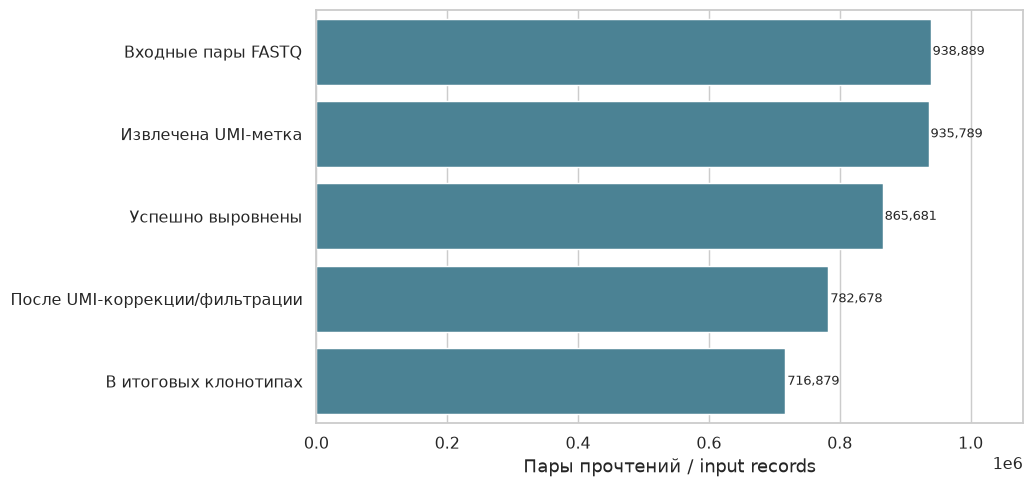

,stage,count
0,"Различные UMI до коррекции, среди выравниваний",175450
1,После коррекции последовательностей UMI,163191
2,Группы UMI после фильтра покрытия,103842
3,Сумма uniqueMoleculeCount в экспорте,90924


In [ ]:
flow=pd.DataFrame([
    ('Входные пары FASTQ',align['totalReadsProcessed']),
    ('Извлечена UMI-метка',align['tagParsingReport']['matched']),
    ('Успешно выровнены',align['aligned']),
    ('После UMI-коррекции/фильтрации',refine['correctionReport']['outputRecords']),
    ('В итоговых клонотипах',assemble['readsInClones'])
],columns=['stage','read_pairs'])
flow['percent_of_raw']=100*flow.read_pairs/align['totalReadsProcessed']
flow.to_csv(RESULTS/'bcr_processing_flow.csv',index=False)
qc=pd.DataFrame([{'step':x['step'],'metric':x['payload'].get('labelOverride',x['check']['label']),'status':x['status'],'fraction':x['payload']['value'],'printed_value':x['payload']['printedValue']}for x in qc_report])
qc.to_csv(RESULTS/'bcr_qc_summary.csv',index=False)
display(flow);display(qc[['metric','printed_value','status']])
raw_retention=assemble['readsInClones']/align['totalReadsProcessed']
assemble_retention=assemble['readsInClones']/assemble['totalReadsProcessed']
reported_retention=next(x['payload']['value']for x in qc_report if x['check']['type']=='ReadsUsedInClonotypes')
assert np.isclose(assemble_retention,reported_retention)
display(Markdown(f'В клонотипы попало **{assemble["readsInClones"]:,} / {align["totalReadsProcessed"]:,} = {raw_retention:.2%}** исходных пар. QC показывает **{assemble_retention:.2%}**, но это доля от **{assemble["totalReadsProcessed"]:,}** записей, оставшихся после UMI-фильтрации.'))
plt.figure(figsize=(10,4.8))
ax=sns.barplot(data=flow,x='read_pairs',y='stage',color='#3f88a0')
for i,n in enumerate(flow.read_pairs):ax.text(n+3000,i,f'{n:,}',va='center',fontsize=9)
ax.set_xlim(0,align['totalReadsProcessed']*1.15);ax.set_xlabel('Пары прочтений / input records');ax.set_ylabel('')
savefig('bcr_processing_flow')
cor=refine['correctionReport'];step=cor['steps'][0];fil=cor['filterReport'];pre=assemble['preCloneAssemblerReport']
umi_stages=pd.DataFrame([
    ('Различные UMI до коррекции, среди выравниваний',step['inputDiversity']),
    ('После коррекции последовательностей UMI',step['outputDiversity']),
    ('Группы UMI после фильтра покрытия',fil['numberOfGroupsAccepted']),
    ('Сумма uniqueMoleculeCount в экспорте',int(raw.uniqueMoleculeCount.sum()))
],columns=['stage','count'])
umi_stages.to_csv(RESULTS/'bcr_umi_stages.csv',index=False);display(umi_stages)
threshold=fil['operatorReports'][0]['operatorReport']['threshold']
print('Порог покрытия UMI-группы (выбран автоматически):',threshold,'прочтений')
print('Записей отброшено фильтром:',cor['inputRecords']-cor['outputRecords'])


**Про предупреждения.** Порог покрытия UMI-группы равен 3, и из 865 681 выровненной записи отфильтровано 83 003 (9,59%). В QC две строки WARN с 9,59%, но это один и тот же отсев, складывать их не надо. Коррекция затронула 12 259 из 175 450 UMI (6,99%). Порог ради большего числа вариантов мы не снижали.

В 2836 группах нашлось больше одного консенсуса, доля коллизий штрихкодов 2,73% (WARN). Значит, правило «один UMI — одна молекула» выполняется не всегда. Поэтому сумму UMI-счётчиков мы берём как вес наблюдений, а не как число клеток или уникальных молекул. Откуда берутся коллизии, по отчёту понять нельзя. Описание проверок QC: [MiXCR, List of quality checks](https://mixcr.com/mixcr/reference/qc-list-of-checks/).

## 3. Фильтр продуктивных CDR3

Используем `Filter(functionality="f", by_umi=True)`: CDR3aa считается продуктивной, если в ней нет `*` и `_` (так же, как в TCR-части). Символы из частично покрытого FR4 не учитываются. После фильтра частоты пересчитываются заново. Показатель `nonFunctional` в отчёте MiXCR считается по другому критерию, поэтому приводим его отдельно.

In [ ]:
mask=raw.aaSeqCDR3.notna() & ~raw.aaSeqCDR3.str.contains(r'[*_]',regex=True,na=False)
raw_func=raw.loc[mask].copy()
functional=clf.Filter(functionality='f',by_umi=True).apply(raw)
assert len(functional)==len(raw_func)
assert int(functional['count'].sum())==int(raw_func.uniqueMoleculeCount.sum())
assert np.isclose(functional['freq'].sum(),1)
assert functional.cdr3nt.str.len().eq(3*functional.cdr3aa.str.len()).all()
assert functional.cdr3aa.str.fullmatch('[ACDEFGHIKLMNPQRSTVWY]+').all()
colnames=get_column_names_from_clonoset(raw)
assert colnames['umi_column']=='uniqueMoleculeCount'
raw_stats=stats.calculate_clonoset_stats_cl(raw)
summary=pd.DataFrame([raw_stats]);summary.to_csv(RESULTS/'bcr_clonoset_stats.csv',index=False)
functional.to_csv(RESULTS/'bcr_functional.tsv',sep='\t',index=False)
display(summary.T.rename(columns={0:'value'}))
report_nonfunc=assemble['clonalChainUsage']['chains']['IGH']['nonFunctional']
inframe_underscore=raw.nSeqCDR3.str.len().mod(3).eq(0)&raw.aaSeqCDR3.str.contains('_',regex=False)
display(Markdown(f'Из **{len(raw):,}** вариантов в экспорте фильтр CDR3 оставил **{len(functional):,}** (**{int(functional["count"].sum()):,}** UMI-наблюдений), отброшено **{int((~mask).sum()):,}**. В отчёте MiXCR nonFunctional = **{report_nonfunc}**. Кроме того, в таблице есть **{int(inframe_underscore.sum())}** CDR3, у которых длина в нуклеотидах кратна трём, но в aaSeqCDR3 стоит `_`; наш фильтр их исключает. Эти два критерия не смешиваем.'))
functional_total=int(functional['count'].sum())


,value
clones,37516.000000
clones_func,36416.000000
clones_func_singletons,24463.000000
clones_func_non_singletons,11953.000000
clones_nonfunc,1100.000000
clones_nonfunc_freq,0.029321
reads,716879.000000
reads_func,706820.000000
reads_nonfunc,10059.000000
reads_nonfunc_freq,0.014032


Из **37,516** вариантов в экспорте фильтр CDR3 оставил **36,416** (**89,665** UMI-наблюдений), отброшено **1,100**. В отчёте MiXCR nonFunctional = **947**. Кроме того, в таблице есть **153** CDR3, у которых длина в нуклеотидах кратна трём, но в aaSeqCDR3 стоит `_`; наш фильтр их исключает. Эти два критерия не смешиваем.

## 4. Длины и свойства CDR3

Распределение длин взвешено по `uniqueMoleculeCount`. Невзвешенное распределение по вариантам MiXCR показано рядом, но на распределение по клеткам оно не похоже. Физико-химические свойства считает `repseq.stats.calculate_cdr3_properties_cl`, как на семинаре; путь к таблице свойств аминокислот задан внутри установленного пакета.

,value
mean_cdr3nt_len,54.231462
mean_insert_size,13.003446
zero_insert_freq,0.010740
mean_frequency,0.000027
cdr3_5_hydropathy,-1.059624
cdr3_full_hydropathy,-6.294754
cdr3_5_charge,-0.087972
cdr3_full_charge,-0.142330
cdr3_5_polarity,2.330385
cdr3_full_polarity,8.240941


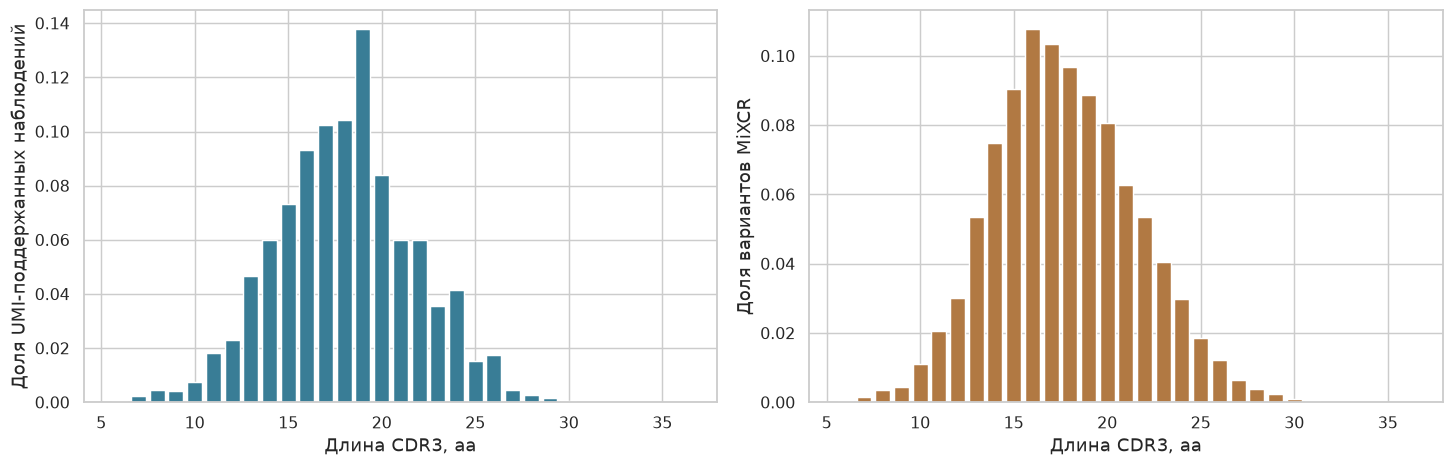

In [ ]:
props=stats.calculate_cdr3_properties_cl(functional)
props['mean_cdr3aa_len']=float(np.average(functional.cdr3aa.str.len(),weights=functional['count']))
props['mean_cdr3aa_len_read_weighted']=float(np.average(raw_func.aaSeqCDR3.str.len(),weights=raw_func.readCount))
pd.DataFrame([props]).to_csv(RESULTS/'bcr_cdr3_properties.csv',index=False)
display(pd.DataFrame([props]).T.rename(columns={0:'value'}))
lengths=functional.assign(length_aa=functional.cdr3aa.str.len(),length_nt=functional.cdr3nt.str.len())
ld=lengths.groupby('length_aa').agg(umi=('count','sum'),variants=('count','size')).reset_index()
ld['umi_fraction']=ld.umi/ld.umi.sum();ld['variant_fraction']=ld.variants/ld.variants.sum()
ld.to_csv(RESULTS/'bcr_cdr3_lengths.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,4.6))
axes[0].bar(ld.length_aa,ld.umi_fraction,color='#397d96');axes[0].set_xlabel('Длина CDR3, aa');axes[0].set_ylabel('Доля UMI-поддержанных наблюдений')
axes[1].bar(ld.length_aa,ld.variant_fraction,color='#b17943');axes[1].set_xlabel('Длина CDR3, aa');axes[1].set_ylabel('Доля вариантов MiXCR')
savefig('bcr_cdr3_lengths')


## 5. V/J-гены и изотипы

Если аннотация неоднозначная, берём первый hit (так делает `repseq.Filter`); полные списки кандидатов остаются в экспорте MiXCR. Частоты V/J нормируются на функциональный репертуар IGH. Изотипы считаем после того же фильтра CDR3 по **`uniqueMoleculeCount`**, а частоты по прочтениям даём для сравнения, чтобы видеть, как влияет выбор счётчика.

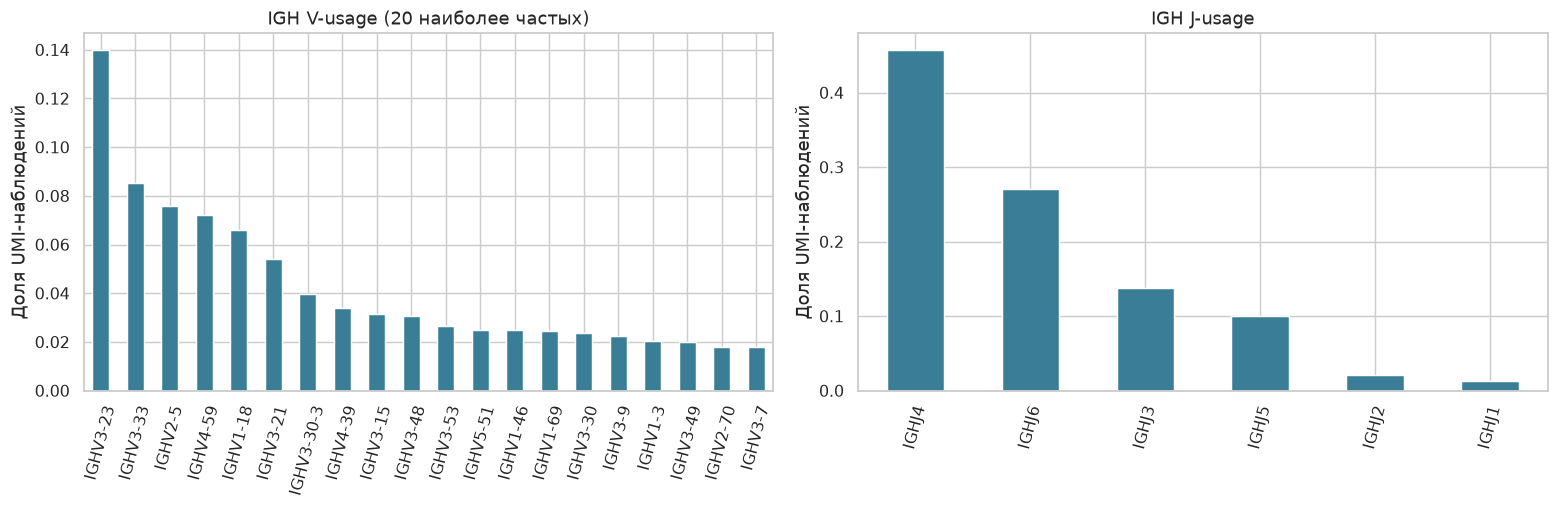

IGHV3-23      0.139820
IGHV3-33      0.085284
IGHV2-5       0.075682
IGHV4-59      0.072280
IGHV1-18      0.065845
IGHV3-21      0.054179
IGHV3-30-3    0.039793
IGHV4-39      0.034038
IGHV3-15      0.031339
IGHV3-48      0.030469
Name: umi_fraction, dtype: float64

IGHJ4    0.456934
IGHJ6    0.271076
IGHJ3    0.137635
IGHJ5    0.100028
IGHJ2    0.020900
IGHJ1    0.013428
Name: umi_fraction, dtype: float64

,umi,reads,variants,umi_fraction,read_fraction
isotype,,,,,
IgM,36711,291643,19308,0.409424,0.412613
IgD,19335,160058,14637,0.215636,0.226448
IgG1,16683,130305,1171,0.186059,0.184354
IgA1,10279,74830,830,0.114638,0.105869
IgG3,2925,21386,138,0.032621,0.030257
IgA2,2434,19061,187,0.027145,0.026967
IgG2,1277,9399,136,0.014242,0.013298
IgG4,15,87,3,0.000167,0.000123
Unassigned,5,47,5,0.000056,0.000066


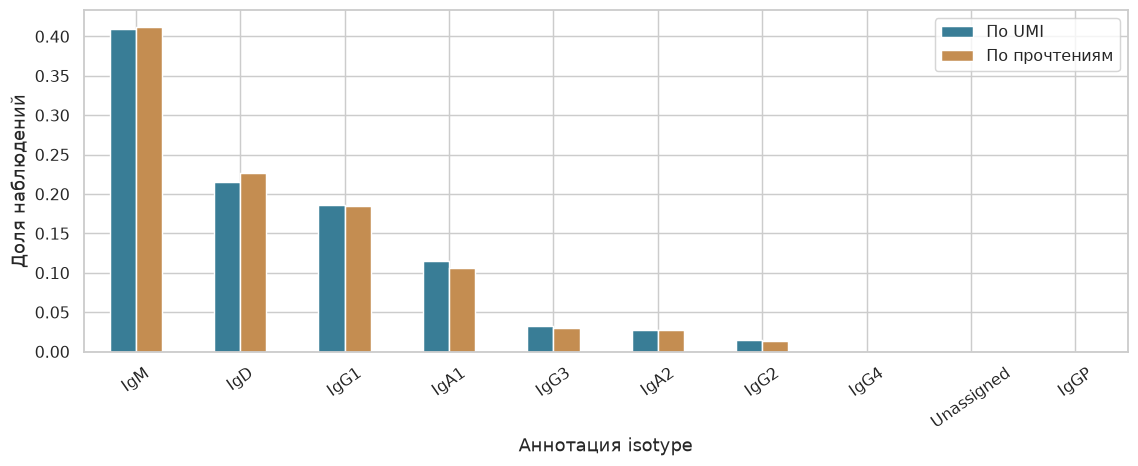

In [ ]:
usage_tables={}
fig,axes=plt.subplots(1,2,figsize=(15,5))
for ax,segment in zip(axes,['v','j']):
    u=pd.Series(stats.calc_segment_usage_cl(functional,segment=segment),name='umi_fraction').sort_values(ascending=False)
    assert np.isclose(u.sum(),1)
    u.rename_axis('gene').to_csv(RESULTS/f'bcr_{segment}_usage.csv')
    usage_tables[segment]=u
    shown=u.head(20)if segment=='v'else u
    shown.plot.bar(ax=ax,color='#397d96');ax.set_title(f'IGH {segment.upper()}-usage'+(' (20 наиболее частых)'if segment=='v'else ''));ax.set_ylabel('Доля UMI-наблюдений');ax.tick_params(axis='x',rotation=75)
savefig('bcr_vj_usage')
display(usage_tables['v'].head(10));display(usage_tables['j'])
iso=raw_func.assign(isotype=raw_func.isotype.fillna('Unassigned')).groupby('isotype',dropna=False).agg(umi=('uniqueMoleculeCount','sum'),reads=('readCount','sum'),variants=('cloneId','size')).sort_values('umi',ascending=False)
assert int(iso.umi.sum())==functional_total
iso['umi_fraction']=iso.umi/iso.umi.sum();iso['read_fraction']=iso.reads/iso.reads.sum()
iso.to_csv(RESULTS/'bcr_isotypes.csv');display(iso)
iso[['umi_fraction','read_fraction']].plot.bar(figsize=(11,4.6),color=['#397d96','#c48d51'])
plt.ylabel('Доля наблюдений');plt.xlabel('Аннотация isotype');plt.xticks(rotation=35);plt.legend(['По UMI','По прочтениям']);savefig('bcr_isotypes')


## 6. α-разнообразие и клональность

Единица анализа — вариант MiXCR (CDR1–FR4, разделение по C-гену). `richness` — число вариантов. Индекс Шеннона H считаем по UMI-частотам; клональность = `1 − H/log(S)`, обратный индекс Симпсона = `1/Σp²`, эффективное число Шеннона = `exp(H)`.

Эти индексы описывают репертуар последовательностей с весом по UMI. Они не равны числу B-клеток или клеточных линий: частота транскриптов — не то же самое, что частота клеток.

,value
richness,36416.000000
umi_observations,89665.000000
shannon_wiener,9.325583
hill_shannon,11221.459956
clonality,0.112083
inverse_simpson,1994.658513
berger_parker,0.007193
top10_fraction,0.038644
top100_fraction,0.167981
singleton_variant_fraction,0.671765


,weight,richness,shannon_wiener,clonality,inverse_simpson,berger_parker
0,UMI,36416,9.325583,0.112083,1994.658513,0.007193
1,readCount,36416,9.266695,0.117690,1825.383798,0.007106


,cloneId,uniqueMoleculeCount,readCount,isotype,aaSeqCDR3
1,0,645,4928,IgG3,CARDRRTGLWSGYGYMDVW
0,1,445,5023,IgM,CAHSPASQGHFLMTFGGLIIPHFDSW
5,2,370,2763,IgG1,CARDRRTGIWSGYGYMDVW
3,4,353,3010,IgM,CARDPNYDFWSGGDMNVW
17,3,353,1566,IgA1,CARSDMLRFVEWTGSYQRFHMDVW
4,5,339,2777,IgM,CTTDLDYYDSSGYRFDCW
2,6,255,3042,IgG1,CAHSSDIIGGSWGFGMDVW
10,7,253,1845,IgA1,CARGGDPRVVVAATDAFDFW
11,8,227,1717,IgG3,CARDRRTGLWSGYGYMDVW
13,9,225,1650,IgG1,CTKDPLSPWFGNFEIFDYW


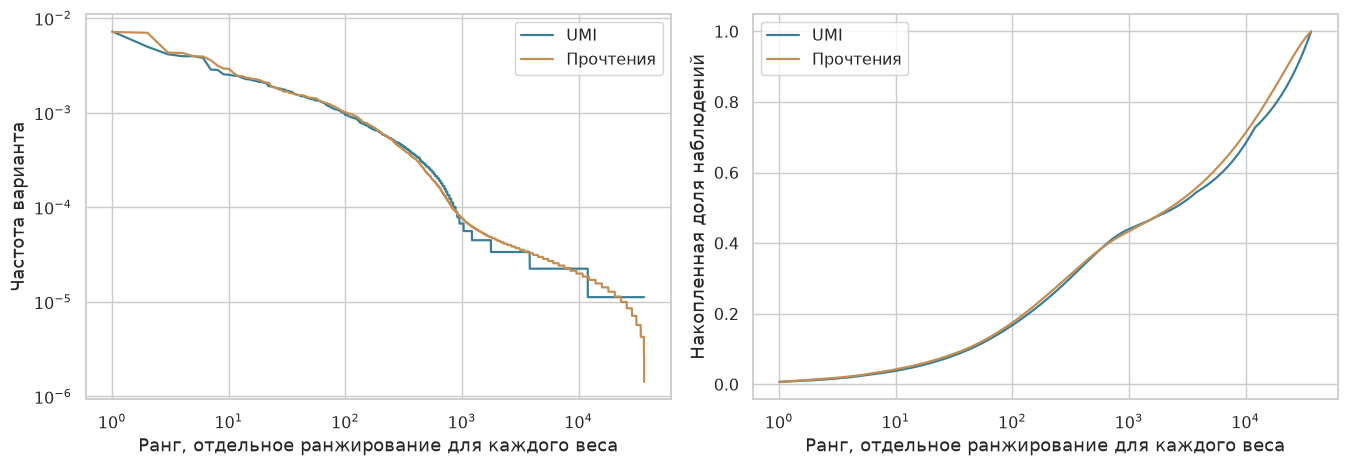

In [ ]:
alpha=stats.calculate_diversity_stats_cl(functional)
alpha['hill_shannon']=float(np.exp(alpha['shannon_wiener']))
alpha['umi_observations']=functional_total
alpha['top10_fraction']=float(functional['count'].nlargest(10).sum()/functional_total)
alpha['top100_fraction']=float(functional['count'].nlargest(100).sum()/functional_total)
alpha['singleton_variant_fraction']=float(functional['count'].eq(1).mean())
alpha['singleton_umi_mass']=float(functional.loc[functional['count'].eq(1),'count'].sum()/functional_total)
pd.DataFrame([alpha]).to_csv(RESULTS/'bcr_diversity.csv',index=False)
selected=['richness','umi_observations','shannon_wiener','hill_shannon','clonality','inverse_simpson','berger_parker','top10_fraction','top100_fraction','singleton_variant_fraction','goods_coverage']
display(pd.Series({k:alpha[k]for k in selected},name='value').to_frame())
read_functional=clf.Filter(functionality='f',by_umi=False).apply(raw)
read_alpha=stats.calculate_diversity_stats_cl(read_functional)
weight_comparison=pd.DataFrame([{'weight':'UMI',**{k:alpha[k]for k in ['richness','shannon_wiener','clonality','inverse_simpson','berger_parker']}},{'weight':'readCount',**{k:read_alpha[k]for k in ['richness','shannon_wiener','clonality','inverse_simpson','berger_parker']}}])
weight_comparison.to_csv(RESULTS/'bcr_weight_sensitivity.csv',index=False);display(weight_comparison)
top=raw_func.sort_values('uniqueMoleculeCount',ascending=False).copy()
top['umi_fraction_functional']=top.uniqueMoleculeCount/functional_total
top['read_fraction_functional']=top.readCount/top.readCount.sum()
top[['cloneId','uniqueMoleculeCount','readCount','umi_fraction_functional','read_fraction_functional','isotype','aaSeqCDR3','allVHitsWithScore','allJHitsWithScore']].head(30).to_csv(RESULTS/'bcr_top_clonotypes.csv',index=False)
display(top[['cloneId','uniqueMoleculeCount','readCount','isotype','aaSeqCDR3']].head(10))
fig,axes=plt.subplots(1,2,figsize=(13,4.6))
for weights,label,color in [(functional['count'],'UMI','#397d96'),(raw_func.readCount,'Прочтения','#c48d51')]:
    freq=np.sort(np.asarray(weights,dtype=float))[::-1]/np.sum(weights)
    ranks=np.arange(1,len(freq)+1)
    axes[0].plot(ranks,freq,label=label,color=color);axes[1].plot(ranks,np.cumsum(freq),label=label,color=color)
axes[0].set_xscale('log');axes[0].set_yscale('log');axes[0].set_ylabel('Частота варианта')
axes[1].set_xscale('log');axes[1].set_ylabel('Накопленная доля наблюдений')
for ax in axes:ax.set_xlabel('Ранг, отдельное ранжирование для каждого веса');ax.legend()
savefig('bcr_rank_abundance')


## 7. Конвергенция и определение клонотипа

Конвергенция — отношение числа уникальных CDR3nt к числу уникальных CDR3aa; варианты `_v` и `_vj` дополнительно учитывают V и V+J. Для BCR это просто описательная величина: не разобрав SHM-линии, нельзя уверенно связывать её с конвергентной V(D)J-рекомбинацией.

Для проверки устойчивости варианты также объединены по CDR3nt+V+J и CDR3aa+V+J (при этом теряются различия в CDR1/CDR2/FR и C-гене). Это не реконструкция B-клеточных линий.

,value
convergence,1.007730
convergence_v,1.007489
convergence_vj,1.007415


,definition,richness,shannon_wiener,clonality,inverse_simpson,berger_parker
0,MiXCR CDR1–FR4 + C,36416,9.325583,0.112083,1994.658513,0.007193
1,CDR3nt+V+J,29619,9.048373,0.121191,1069.777355,0.019127
2,CDR3aa+V+J,29401,8.937733,0.131313,564.829522,0.033781


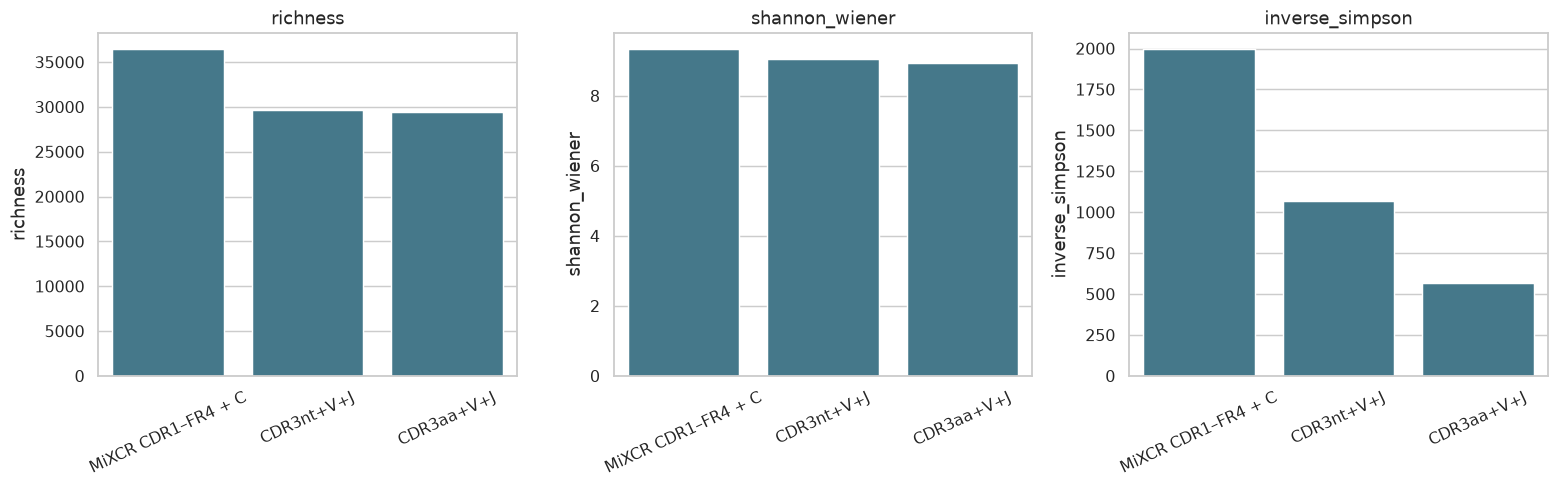

In [ ]:
convergence=stats.calculate_convergence_cl(functional)
pd.DataFrame([convergence]).to_csv(RESULTS/'bcr_convergence.csv',index=False);display(pd.Series(convergence,name='value').to_frame())
definitions=[('MiXCR CDR1–FR4 + C',functional)]
for label,keys in [('CDR3nt+V+J',['cdr3nt','v','j']),('CDR3aa+V+J',['cdr3aa','v','j'])]:
    pooled=functional.groupby(keys,dropna=False)['count'].sum().reset_index();pooled['freq']=pooled['count']/pooled['count'].sum()
    assert int(pooled['count'].sum())==functional_total
    definitions.append((label,pooled))
definition_rows=[]
for label,r in definitions:
    a=stats.calculate_diversity_stats_cl(r)
    definition_rows.append({'definition':label,**{k:a[k]for k in ['richness','shannon_wiener','clonality','inverse_simpson','berger_parker']}})
definition_summary=pd.DataFrame(definition_rows)
definition_summary.to_csv(RESULTS/'bcr_definition_sensitivity.csv',index=False);display(definition_summary)
fig,axes=plt.subplots(1,3,figsize=(15,4.8))
for ax,m in zip(axes,['richness','shannon_wiener','inverse_simpson']):
    sns.barplot(data=definition_summary,x='definition',y=m,ax=ax,color='#397d96');ax.set_xlabel('');ax.set_title(m);ax.tick_params(axis='x',rotation=25)
savefig('bcr_definition_sensitivity')


## 8. Rarefaction и зависимость от глубины

Делаем субвыборки без возвращения по UMI-счётчикам на глубинах **25 000** и **50 000** (оба значения меньше размера функционального набора), по пять повторов (seed 100–104). Повторы технические, не биологические; основной α-анализ сделан на полном наборе.

Заливка на графике — ±1 SD по пяти субвыборкам, а не доверительный интервал между индивидами. Последняя точка — весь наблюдаемый репертуар, экстраполяции нет.

Наша быстрая субвыборка в точности совпала с repseq.Filter (проверка: seed=100, depth=1000).


,depth,richness_mean,richness_sd
0,100,98.2,2.167948
1,185,178.6,4.393177
2,344,322.0,5.049752
3,638,570.8,7.190271
4,1184,997.6,8.080842
5,2198,1710.0,9.165151
6,4078,2917.2,11.300442
7,7567,4926.0,28.591957
8,14039,8344.6,36.239481
9,25000,13612.4,76.728743


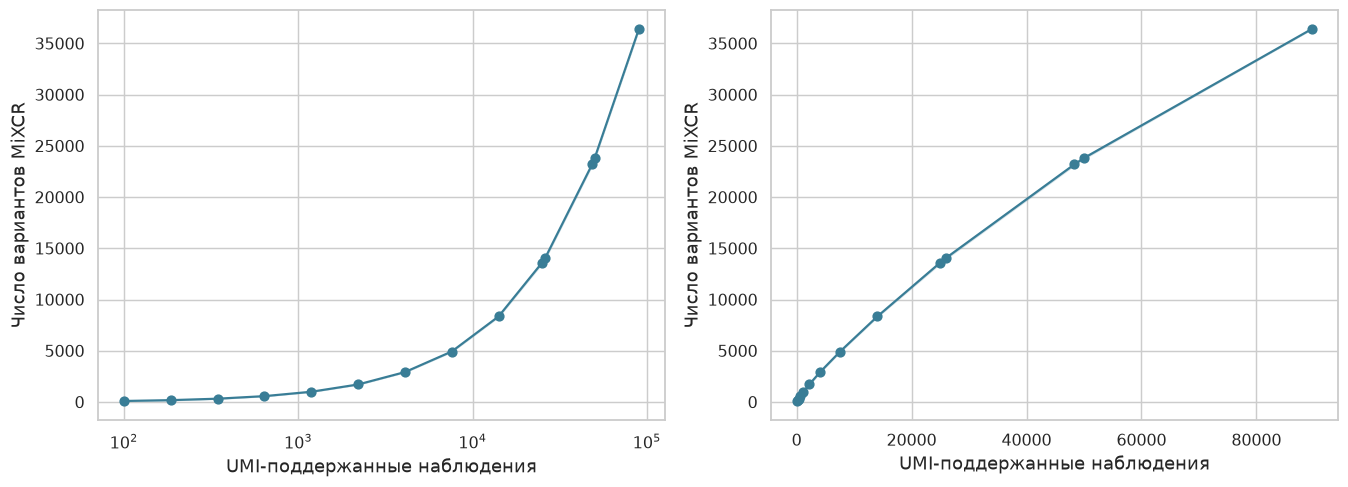

,depth,richness_mean,richness_sd,shannon_mean,clonality_mean,inverse_simpson_mean
0,25000,13612.4,76.728743,8.779654,0.077644,1935.380231
1,50000,23815.0,65.099923,9.098422,0.097206,1973.760698
2,89665,36416.0,0.000000,9.325583,0.112083,1994.658513


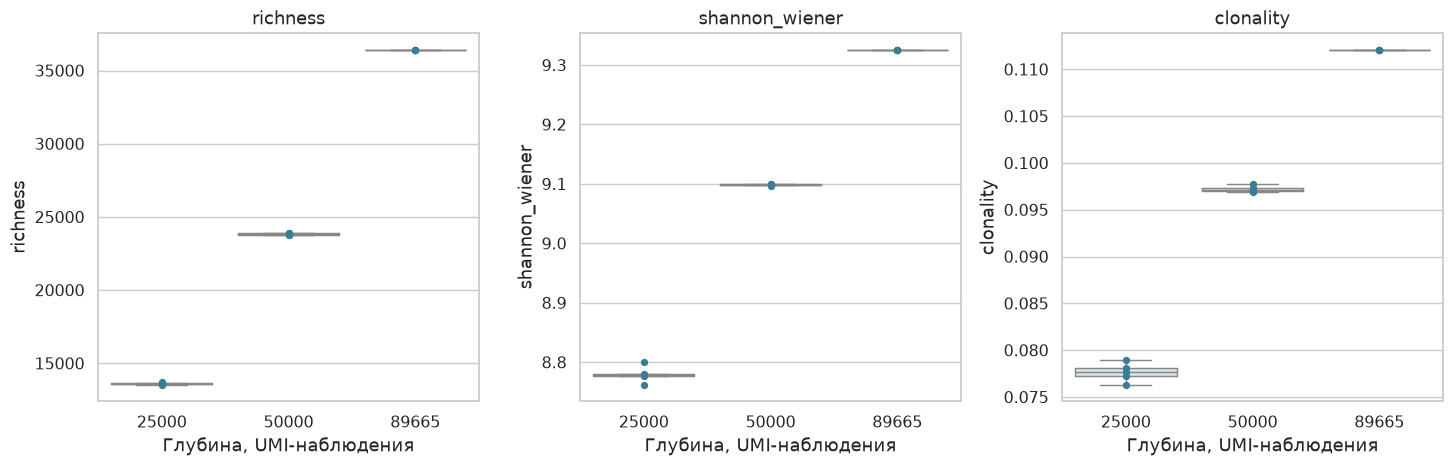

In [ ]:
def sample_clonoset(r,depth,seed):
    r=r.sort_values('count',ascending=False).reset_index(drop=True)
    counts=r['count'].to_numpy(dtype=np.int64);total=int(counts.sum())
    if depth==total:return r.copy()
    positions=np.array(random.Random(seed).sample(range(total),int(depth)),dtype=np.int64)
    clone_indices=np.searchsorted(np.cumsum(counts),positions,side='right')
    counts_sampled=np.bincount(clone_indices,minlength=len(r))
    out=r.loc[counts_sampled>0].copy();out['count']=counts_sampled[counts_sampled>0];out['freq']=out['count']/depth
    assert int(out['count'].sum())==depth
    return out

reference=clf.Filter(functionality='f',by_umi=True,downsample=1000,seed=SEED).apply(functional)
fast=sample_clonoset(functional,1000,SEED)
pd.testing.assert_frame_equal(reference[['cdr3nt','count']].reset_index(drop=True),fast[['cdr3nt','count']].reset_index(drop=True),check_dtype=False)
print('Наша быстрая субвыборка в точности совпала с repseq.Filter (проверка: seed=100, depth=1000).')
depths=sorted(set([int(x)for x in np.geomspace(100,functional_total,12)]+[25000,50000,functional_total]))
rare_rows=[]
for d in depths:
    richness=[len(sample_clonoset(functional,d,SEED+k))for k in range(ITERATIONS)]
    rare_rows.append({'depth':d,'richness_mean':float(np.mean(richness)),'richness_sd':float(np.std(richness,ddof=1))})
rarefaction=pd.DataFrame(rare_rows)
rarefaction.to_csv(RESULTS/'bcr_rarefaction.csv',index=False);display(rarefaction)
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
for ax in axes:
    ax.plot(rarefaction.depth,rarefaction.richness_mean,marker='o',color='#397d96')
    ax.fill_between(rarefaction.depth,rarefaction.richness_mean-rarefaction.richness_sd,rarefaction.richness_mean+rarefaction.richness_sd,alpha=.2,color='#397d96')
    ax.set_xlabel('UMI-поддержанные наблюдения');ax.set_ylabel('Число вариантов MiXCR')
axes[0].set_xscale('log');savefig('bcr_rarefaction')
iteration_rows=[]
for d in [25000,50000,functional_total]:
    for k in range(ITERATIONS):
        r=sample_clonoset(functional,d,SEED+k)
        a=stats.calculate_diversity_stats_cl(r)
        iteration_rows.append({'depth':d,'iteration':k,**{m:a[m]for m in ['richness','shannon_wiener','clonality','inverse_simpson']}})
iterations=pd.DataFrame(iteration_rows)
iterations.to_csv(RESULTS/'bcr_depth_iterations.csv',index=False)
depth_summary=iterations.groupby('depth').agg(richness_mean=('richness','mean'),richness_sd=('richness','std'),shannon_mean=('shannon_wiener','mean'),clonality_mean=('clonality','mean'),inverse_simpson_mean=('inverse_simpson','mean')).reset_index()
depth_summary.to_csv(RESULTS/'bcr_depth_sensitivity.csv',index=False);display(depth_summary)
fig,axes=plt.subplots(1,3,figsize=(14,4.6))
for ax,m in zip(axes,['richness','shannon_wiener','clonality']):
    sns.boxplot(data=iterations,x='depth',y=m,ax=ax,color='#d6e6ec',showfliers=False)
    sns.stripplot(data=iterations,x='depth',y=m,ax=ax,color='#397d96',jitter=False)
    ax.set_title(m);ax.set_xlabel('Глубина, UMI-наблюдения')
savefig('bcr_depth_sensitivity')


## 9. Интерпретация результатов

Текст ниже собирается кодом из посчитанных таблиц. Образец один, поэтому тесты между группами, F2 и MDS не делались, а технические субвыборки не заменяют группы доноров.

In [ ]:
igmd=float(iso.reindex(['IgM','IgD']).umi_fraction.sum())
igg=float(iso.loc[iso.index.to_series().str.match(r'IgG[1-4]$',na=False),'umi_fraction'].sum())
iga=float(iso.loc[iso.index.to_series().str.match(r'IgA[12]$',na=False),'umi_fraction'].sum())
top_read=raw_func.sort_values('readCount',ascending=False).iloc[0]
top_umi=top.iloc[0]
ds=depth_summary.set_index('depth')
top_v_text=', '.join(f'{gene} ({fraction:.2%})'for gene,fraction in usage_tables['v'].head(3).items())
top_j_text=', '.join(f'{gene} ({fraction:.2%})'for gene,fraction in usage_tables['j'].head(3).items())
md_variant_fraction=float(iso.reindex(['IgM','IgD']).variants.sum()/len(functional))
interp=f"""### Объём и качество

Всего на входе **{align['totalReadsProcessed']:,}** пар FASTQ, из них выровнено **{align['aligned']:,} ({align['aligned']/align['totalReadsProcessed']:.2%})**. В итоговые клонотипы попало **{assemble['readsInClones']:,}** пар: это **{raw_retention:.2%}** от исходных и **{assemble_retention:.2%}** от того, что осталось после UMI-фильтрации. Всего получилось **{len(raw):,}** вариантов IGH; после фильтра по продуктивной CDR3 осталось **{len(functional):,}** вариантов и **{functional_total:,}** UMI-наблюдений. Предупреждения QC про коллизии и фильтрацию меток остаются ограничениями этого анализа.

### Состав последовательностей

Средняя длина CDR3 с учётом весов — **{props['mean_cdr3aa_len']:.2f} aa**. Конвергенция CDR3nt/CDR3aa равна **{convergence['convergence']:.4f}**, то есть нуклеотидных CDR3 лишь чуть больше, чем аминокислотных. Это свойство самих последовательностей; откуда они взялись и на какой антиген нацелены, из этого отношения не узнать.

Чаще всего встречаются V-гены **{top_v_text}**, среди J-генов — **{top_j_text}**. Это описание того, какие сегменты представлены в нашем образце (по первой аннотации V/J); контрольного репертуара, с которым можно было бы искать обогащение, у нас нет.

### Варианты и изотипы

По UMI-наблюдениям на IgM приходится **{iso.loc['IgM','umi_fraction']:.2%}**, на IgD — **{iso.loc['IgD','umi_fraction']:.2%}**, вместе **{igmd:.2%}**. IgG1–4 в сумме дают **{igg:.2%}**, IgA1–2 — **{iga:.2%}**. Единственную аннотацию IgGP оставили отдельной строкой; считать её подтверждением отдельной популяции клеток нельзя. Все эти доли посчитаны по молекулярным счётчикам транскриптов IGH, а не по B-клеткам.

Если считать по числу разных вариантов, а не по UMI, то на IgM/IgD приходится **{md_variant_fraction:.2%}**. Расхождение с **{igmd:.2%}** по молекулярному весу показывает, что варианты представлены неравномерно, и подменять одни частоты другими нельзя. У **{int(iso.reindex(['Unassigned']).umi.fillna(0).sum())}** UMI-наблюдений изотип не определён; мы оставили их в знаменателе и вынесли в отдельную строку таблицы.

Самый крупный вариант MiXCR занимает **{alpha['berger_parker']:.2%}**, десять крупнейших — **{alpha['top10_fraction']:.2%}**. По readCount лидирует вариант с cloneId **{int(top_read.cloneId)}**, а по UMI — с cloneId **{int(top_umi.cloneId)}**. Отсюда вывод для адаптации TCR-ноутбука: молекулярный вес нужно выбирать явно и не заменять его ПЦР-прочтениями.

### Разнообразие и зависимость от определения клонотипа

На полном функциональном наборе Shannon H = **{alpha['shannon_wiener']:.4f}**, клональность = **{alpha['clonality']:.4f}**, эффективное число Шеннона = **{alpha['hill_shannon']:.1f}**, обратный Симпсон = **{alpha['inverse_simpson']:.1f}**. Репертуар состоит из множества редких вариантов при неравномерном распределении: у **{alpha['singleton_variant_fraction']:.2%}** вариантов всего один UMI. Это согласуется с порогом в три сырых прочтения на UMI-группу: один молекулярный консенсус может дать целый вариант.

Если объединить варианты по CDR3nt+V+J, остаётся **{int(definition_summary.iloc[1].richness):,}** групп, по CDR3aa+V+J — **{int(definition_summary.iloc[2].richness):,}** вместо **{len(functional):,}** исходных вариантов. Меняются и частоты, и индексы. Поэтому число клонотипов MiXCR нельзя выдавать за число исходных B-клеточных линий.

При глубине 25 000 и 50 000 наблюдений среднее богатство равно **{ds.loc[25000,'richness_mean']:.1f}** и **{ds.loc[50000,'richness_mean']:.1f}**, а на полном наборе — **{len(functional):,}**. Значит, наблюдаемое богатство всё ещё зависит от глубины, а rarefaction не оценивает весь репертуар организма. Пять повторов показывают только случайность субвыборки внутри одного образца.

### Что можно и нельзя заключить

У нас один биологический образец и нет контрольной группы. Поэтому выводов про эффект COVID-19, вакцинации, специфичность к SARS-CoV-2 или различия между донорами сделать нельзя. SHM-деревья и клональные линии мы не строили. Задание выполнено на уровне обработки, QC, состава и разнообразия репертуара IGH."""
display(Markdown(interp))
(RESULTS/'bcr_interpretation.md').write_text(interp)
manifest={'sample_id':SAMPLE,'mixcr_version':align['version'],'preset':'milab-human-rna-ig-umi-multiplex','slurm_job_id':157721,'job_state':'COMPLETED','exit_code':'0:0','elapsed':'00:07:48','seed':SEED,'iterations':ITERATIONS,'weight':'uniqueMoleculeCount','functional_filter':'CDR3aa without * or _','assembling_feature':'{CDR1Begin:FR4End}','split_by_C':True,'python':platform.python_version(),'input_fastq_sha256':server_hashes,'clone_table_sha256':hashlib.file_digest(clone_path.open('rb'),'sha256').hexdigest(),'n_raw_variants':len(raw),'n_cdr3_functional':len(functional),'functional_umi_observations':functional_total}
(RESULTS/'bcr_run_info.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))


Out[9]: 940


### Объём и качество

Всего на входе **938,889** пар FASTQ, из них выровнено **865,681 (92.20%)**. В итоговые клонотипы попало **716,879** пар: это **76.35%** от исходных и **91.59%** от того, что осталось после UMI-фильтрации. Всего получилось **37,516** вариантов IGH; после фильтра по продуктивной CDR3 осталось **36,416** вариантов и **89,665** UMI-наблюдений. Предупреждения QC про коллизии и фильтрацию меток остаются ограничениями этого анализа.

### Состав последовательностей

Средняя длина CDR3 с учётом весов — **18.08 aa**. Конвергенция CDR3nt/CDR3aa равна **1.0077**, то есть нуклеотидных CDR3 лишь чуть больше, чем аминокислотных. Это свойство самих последовательностей; откуда они взялись и на какой антиген нацелены, из этого отношения не узнать.

Чаще всего встречаются V-гены **IGHV3-23 (13.98%), IGHV3-33 (8.53%), IGHV2-5 (7.57%)**, среди J-генов — **IGHJ4 (45.69%), IGHJ6 (27.11%), IGHJ3 (13.76%)**. Это описание того, какие сегменты представлены в нашем образце (по первой аннотации V/J); контрольного репертуара, с которым можно было бы искать обогащение, у нас нет.

### Варианты и изотипы

По UMI-наблюдениям на IgM приходится **40.94%**, на IgD — **21.56%**, вместе **62.51%**. IgG1–4 в сумме дают **23.31%**, IgA1–2 — **14.18%**. Единственную аннотацию IgGP оставили отдельной строкой; считать её подтверждением отдельной популяции клеток нельзя. Все эти доли посчитаны по молекулярным счётчикам транскриптов IGH, а не по B-клеткам.

Если считать по числу разных вариантов, а не по UMI, то на IgM/IgD приходится **93.21%**. Расхождение с **62.51%** по молекулярному весу показывает, что варианты представлены неравномерно, и подменять одни частоты другими нельзя. У **5** UMI-наблюдений изотип не определён; мы оставили их в знаменателе и вынесли в отдельную строку таблицы.

Самый крупный вариант MiXCR занимает **0.72%**, десять крупнейших — **3.86%**. По readCount лидирует вариант с cloneId **1**, а по UMI — с cloneId **0**. Отсюда вывод для адаптации TCR-ноутбука: молекулярный вес нужно выбирать явно и не заменять его ПЦР-прочтениями.

### Разнообразие и зависимость от определения клонотипа

На полном функциональном наборе Shannon H = **9.3256**, клональность = **0.1121**, эффективное число Шеннона = **11221.5**, обратный Симпсон = **1994.7**. Репертуар состоит из множества редких вариантов при неравномерном распределении: у **67.18%** вариантов всего один UMI. Это согласуется с порогом в три сырых прочтения на UMI-группу: один молекулярный консенсус может дать целый вариант.

Если объединить варианты по CDR3nt+V+J, остаётся **29,619** групп, по CDR3aa+V+J — **29,401** вместо **36,416** исходных вариантов. Меняются и частоты, и индексы. Поэтому число клонотипов MiXCR нельзя выдавать за число исходных B-клеточных линий.

При глубине 25 000 и 50 000 наблюдений среднее богатство равно **13612.4** и **23815.0**, а на полном наборе — **36,416**. Значит, наблюдаемое богатство всё ещё зависит от глубины, а rarefaction не оценивает весь репертуар организма. Пять повторов показывают только случайность субвыборки внутри одного образца.

### Что можно и нельзя заключить

У нас один биологический образец и нет контрольной группы. Поэтому выводов про эффект COVID-19, вакцинации, специфичность к SARS-CoV-2 или различия между донорами сделать нельзя. SHM-деревья и клональные линии мы не строили. Задание выполнено на уровне обработки, QC, состава и разнообразия репертуара IGH.

## Воспроизводимость и источники

Чтобы запустить ноутбук, хватит таблицы IGH и отчётов в `results_bcr/`; FASTQ и повторный запуск MiXCR не нужны. Бинарные промежуточные файлы лежат на учебном сервере. Саму обработку можно повторить скриптом `scripts/run_bcr.slurm` из каталога проекта, если есть действующая лицензия (ключи в комплект не входят).

1. `UCB_seminar.ipynb` — схема TCR-анализа, которую адаптировали под IGH.
2. [MiLaboratories Human IG RNA Multiplex](https://mixcr.com/mixcr/guides/milaboratories-human-bcr-rna-multi/) — структура библиотеки и протокол; параметры запуска подтверждены отчётами и снимком пресета 4.7.0.
3. [MiXCR quality checks](https://mixcr.com/mixcr/reference/qc-list-of-checks/) — определения предупреждений QC; знаменатель доли прочтений установлен по JSON этого запуска.
4. [repseq](https://github.com/mmjmike/repseq) v0.1.3 — фильтрация и метрики.